# Exercise project 1


### <i>Dataset evaluation report </i>

<i>Niko Vuokila</i>

---

### Summary

|Topic               |Description               |
|--------------------|--------------------------|
|Dataset Name:       |  Lego sets               |
|Dataset Link:       |    https://www.kaggle.com/datasets/mterzolo/lego-sets           | 
|Target Variable:    |  Price                   | 
|Type of Dataset:    | Regression               |

<br>



---


## Overview

<br>
<br>

##### <b> <u>Step 1a</u>: Inspect the datatypes for each column </b> 

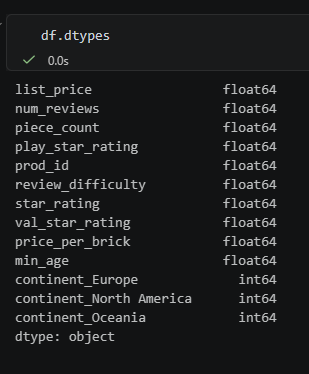

Seems like the categories are correct. They are all in a numerical form.

NOTE! I had prod_id column hanging around in many of the examples. I am aware it should be dropped for ML-purposes. I left it just in case for analytical purposes.


<br><br>
<br>

##### <b> <u>Step 1b</u>: Inspect the shape of the dataset (the number of rows and columns.) </b> 


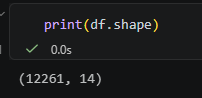 <br>
A quick pandas.shape shows the number of rows and columns.
I believe this is a good number of rows and columns for ML practices, as it is definitely not too little. Especially for learning purposes.

<br>

##### <b> <u>Step 1c</u>: Inspect NaN values, duplicates, zeroes, invalid/nonsensical/problematic values </b> 

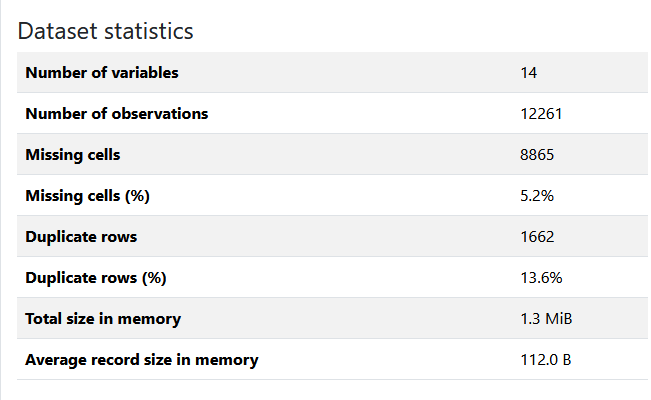 <br>
Now the next picture taken from ydata-profiling shows more issues in our data. Seems like 5.2% of the cells are missing and there are 13.6% duplicate rows. This requires some investigation.

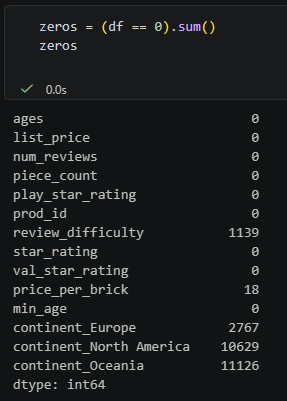 <br>
First of all, checking the zeros reveals a weird number of zeroes in the price per brick category as it should not be a free product. Research shows that it is actually a lego intelligent brick set which actually is not a lego set, but some kind of a device. This can be safely dropped.

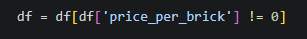 <br>

Rest of the zeroes makes sense, as they are categorical columns which have been converted into numbers.

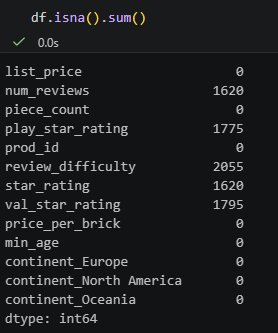<br>

The missing values seem to concentrated in reviews. 

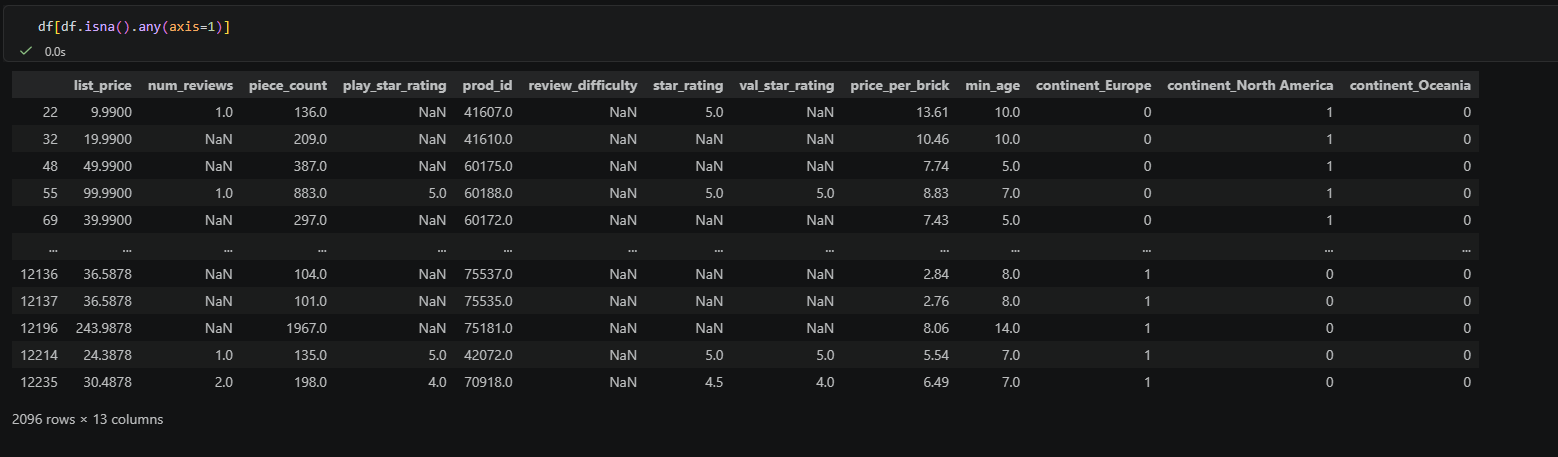 <br>

The values should be safe to drop. These are values that are based on opinions of humans and as the nature of the dataset, filling them would only be an educated guess. After dropping them, there are still over 10k rows left, so I would argue it is safe to drop them.

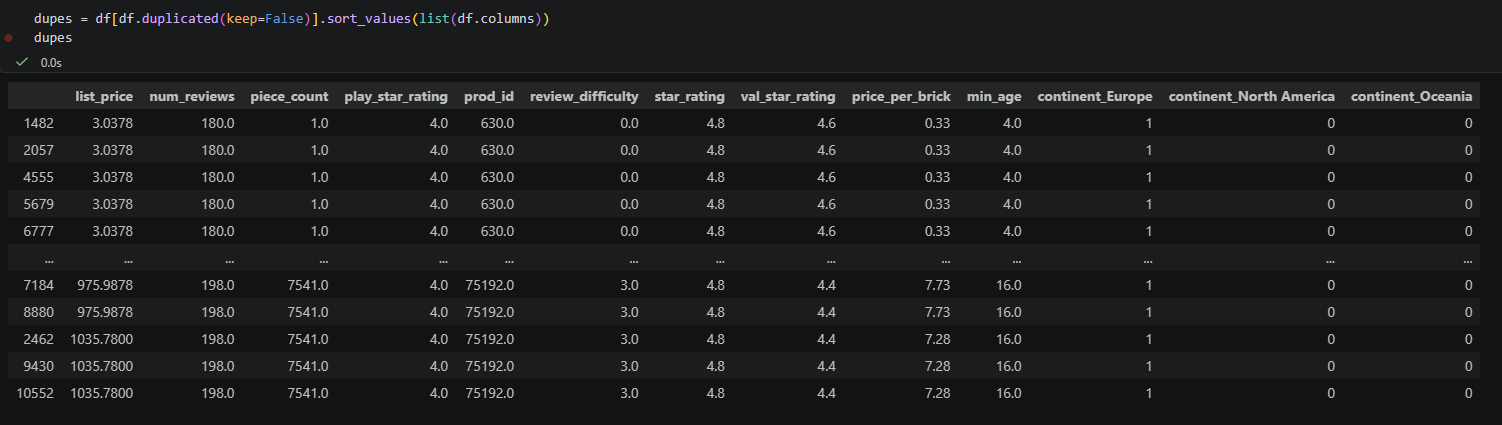 <br>

A quick check shows the dire situation of duplicates in this data. It seems like some products are not just duplicated, but some of them have been inserted into the data many times. These have to be dropped.

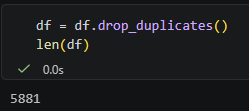 <br>

Tragically, after dropping Na's and duplicates over half of the dataset is gone. Maybe this data is just not great in general?

<br>


</i>

##### <b> <u>Step 1d</u>: Are there any alerts recommendations?</b> 

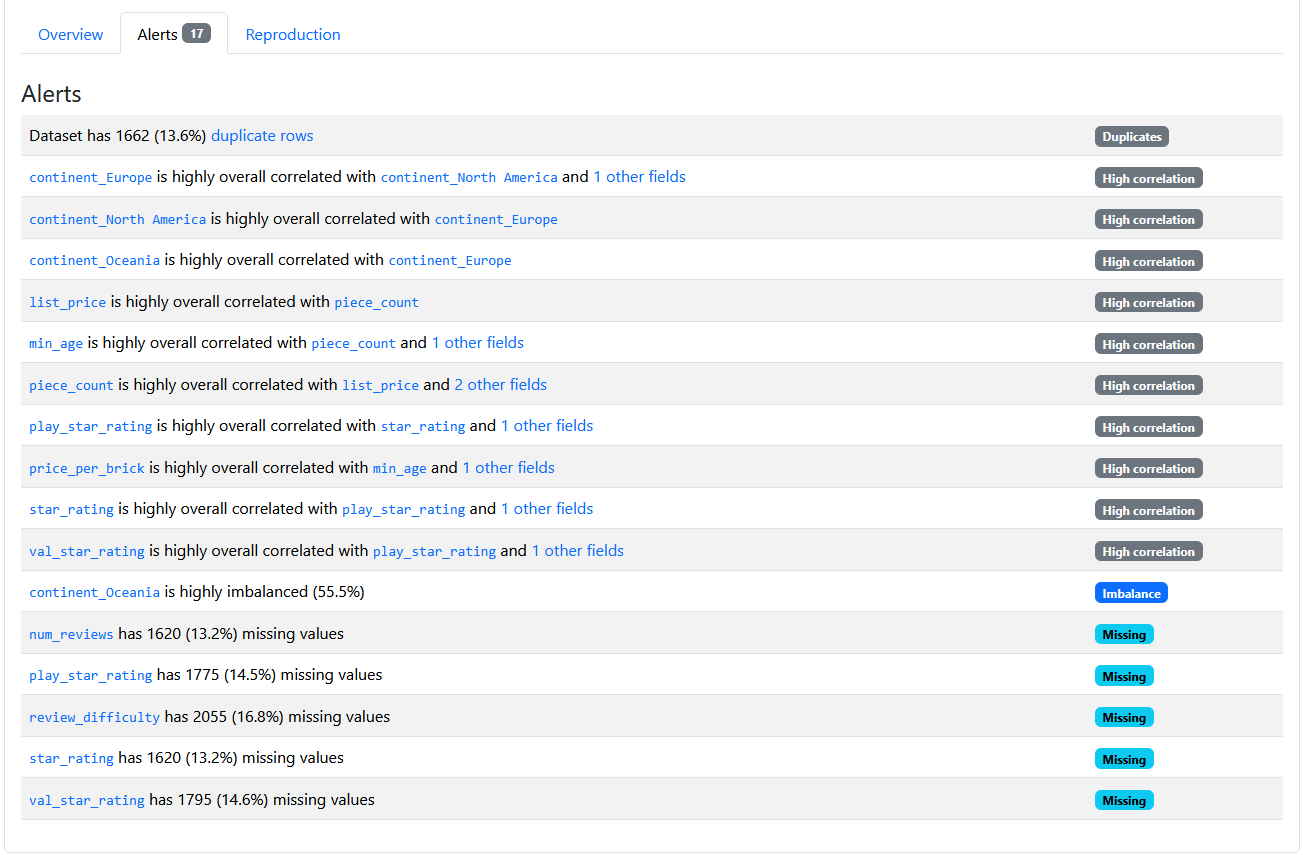 <br>

The concerns shown in ydata-profiling show weird correlations between continents that can be ignored. It also shows a great imbalance in continent_Oceania column.
One issue that it also shows us is the number of NaN-values and duplicates, but they have been taken care of already. 

One weird thing that I found out that while ydata profiling shows 1662 duplicate rows, pandas gives me 5639 rows. <br> 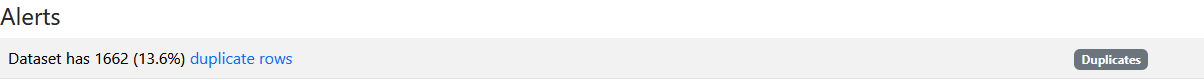 <br>
The issue seems to be in ydata profiling. If one single row is multiplied in the data five times, the function inside ydata profiling will still count this as one duplicate. Even if the reality of duplicates is half of the dataset! 

<br>

---

## Distribution, outliers, imbalances

<br>
<br>

##### <b> <u>Step 2a</u>: Distributions & imbalances</b> 


Most of the features have left-leaning distributions and are not following the standard curve. For example: <br><br>
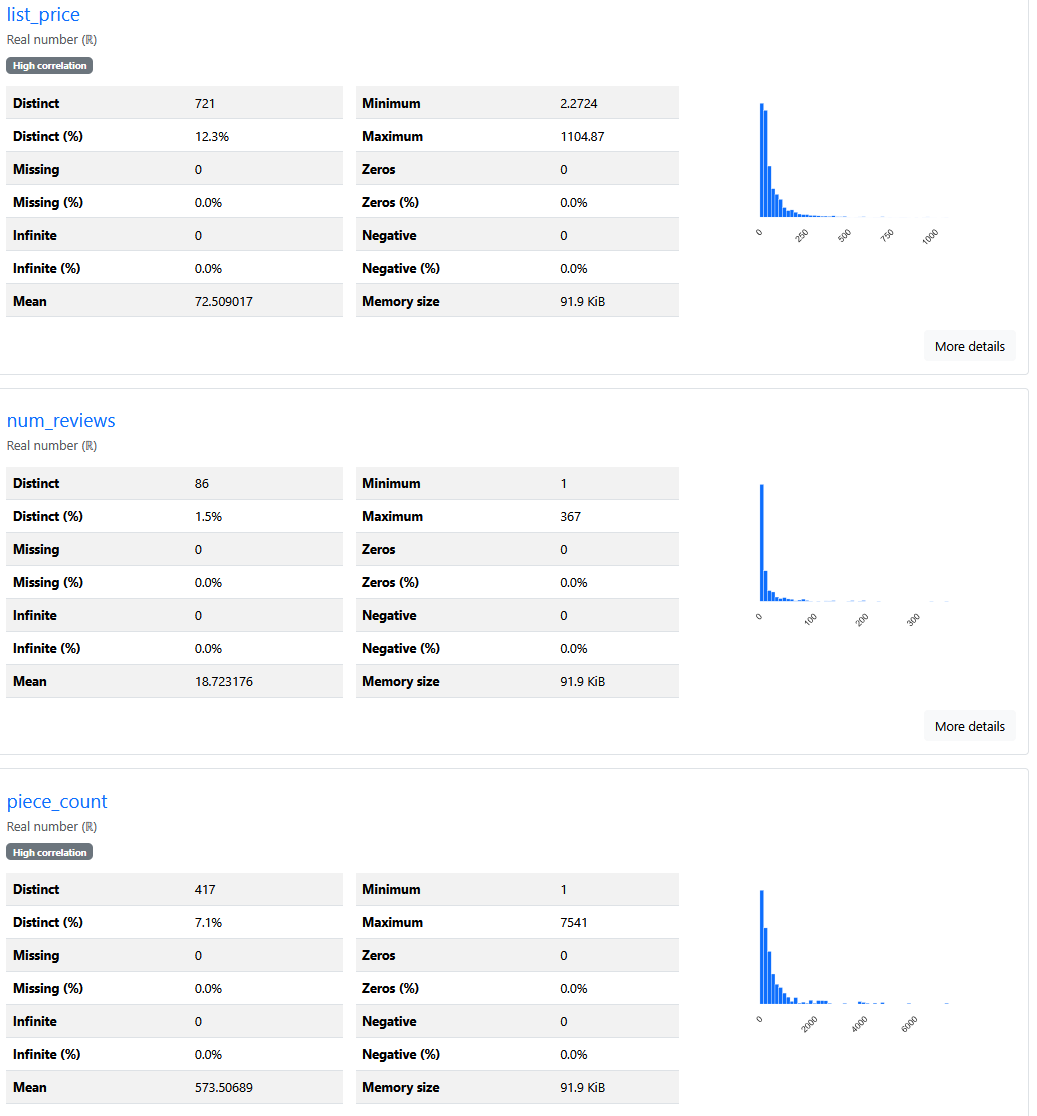 <br>  
Most of the columns have outlier values. Just by looking at this picture, we can learn that most of the legos are on the cheaper side, when the more expensive legos are very sparce in the data.


<br>

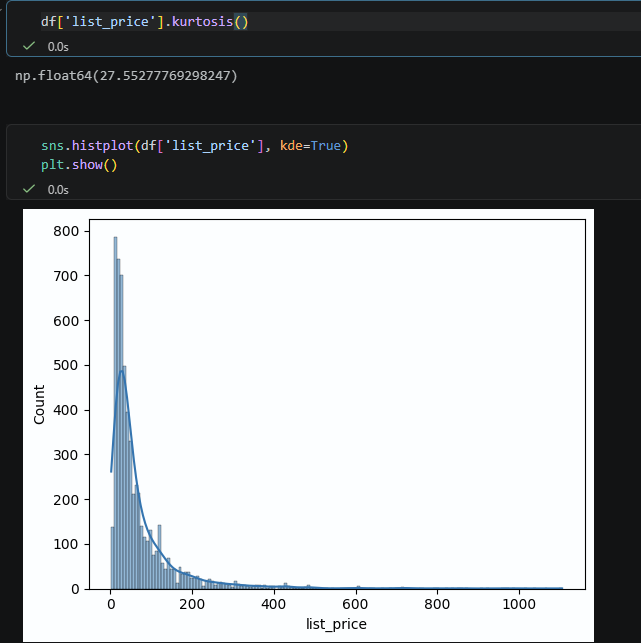 <br>

Looking at the target variable, it already shows us some high kurtosis. The tail of the data points at quite a few extreme values, when most of the data is at the cheaper side. Of course, this is not optimal for ML-training.

<br>


##### <b> <u>Step 2b</u>: Multicollinearity & redundancy </b> 

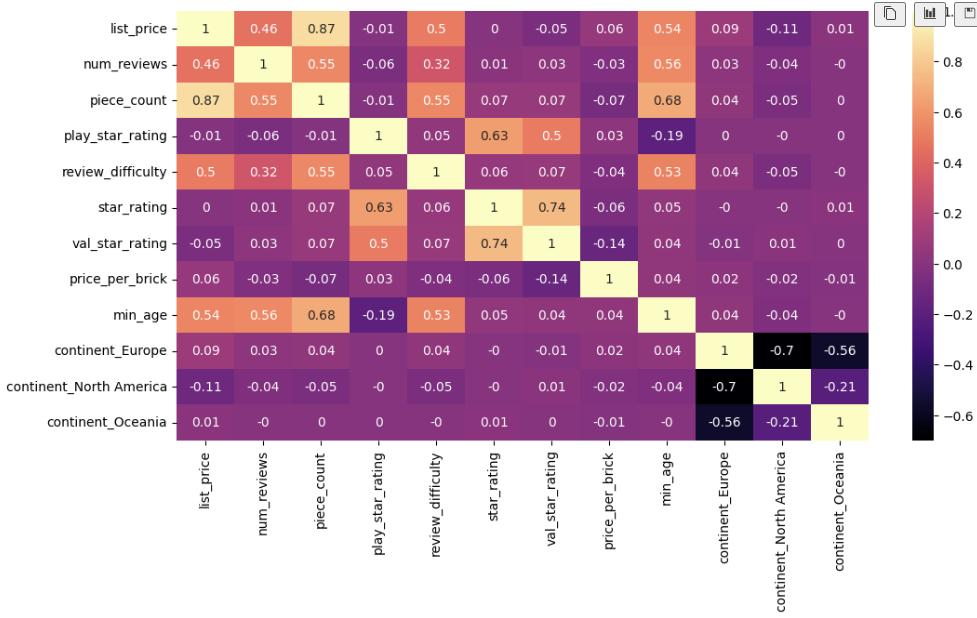 <br>

We can see how the 'price_per_brick' column actually does not correlate with the list_price. List_price and piece_count however are correlated very heavily with each other. This is is a potential risk for for multicollinearity, but I will still keep the column for now.

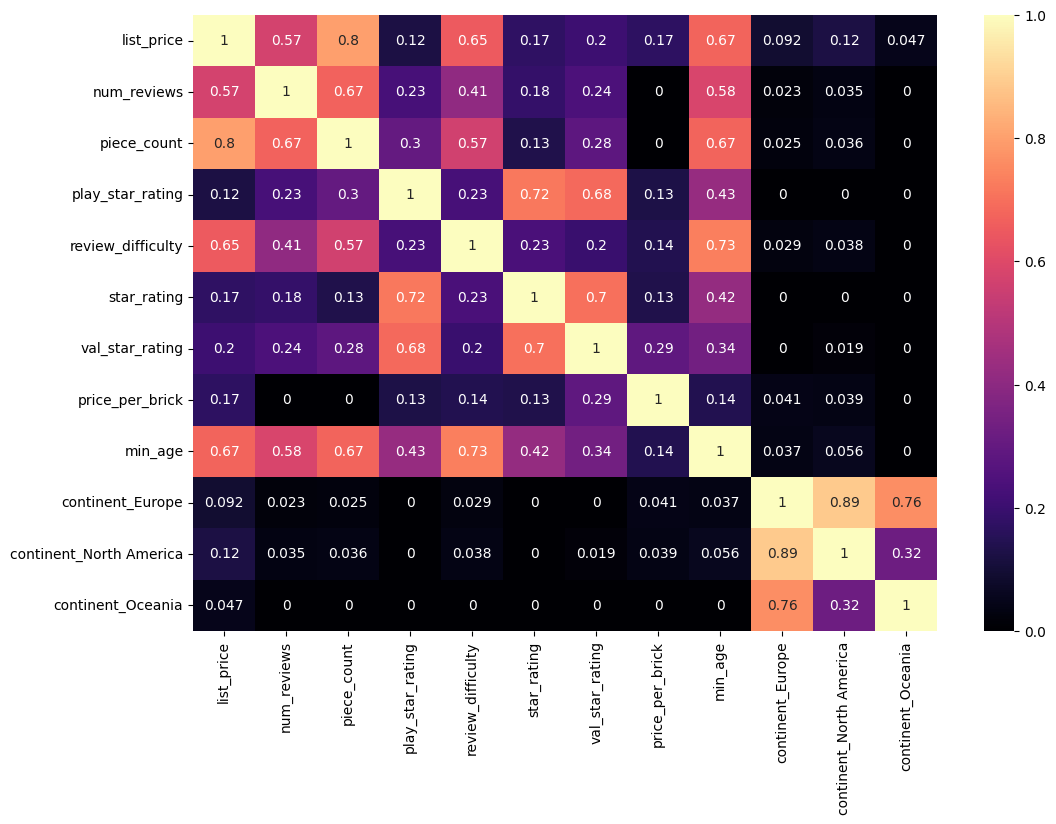 <br>

I also did the phik matrix for fun, but it does not reveal more information we did not learn with the correlation heatmap already. 

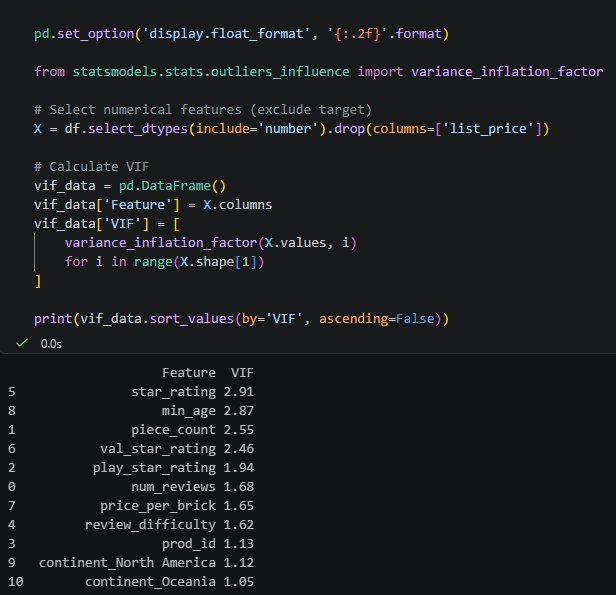

Once again, according to the VIF-test the price_per_brick column does not showcase high multi-collinearity with the list_price. 

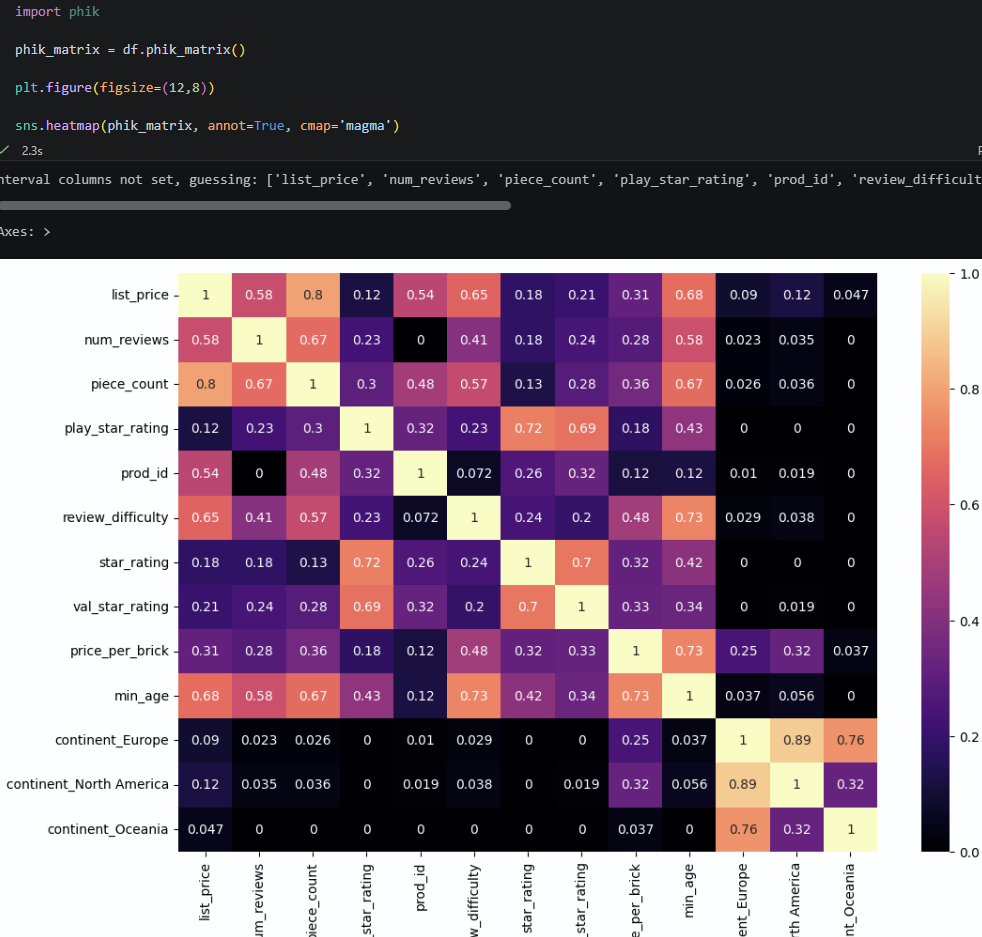
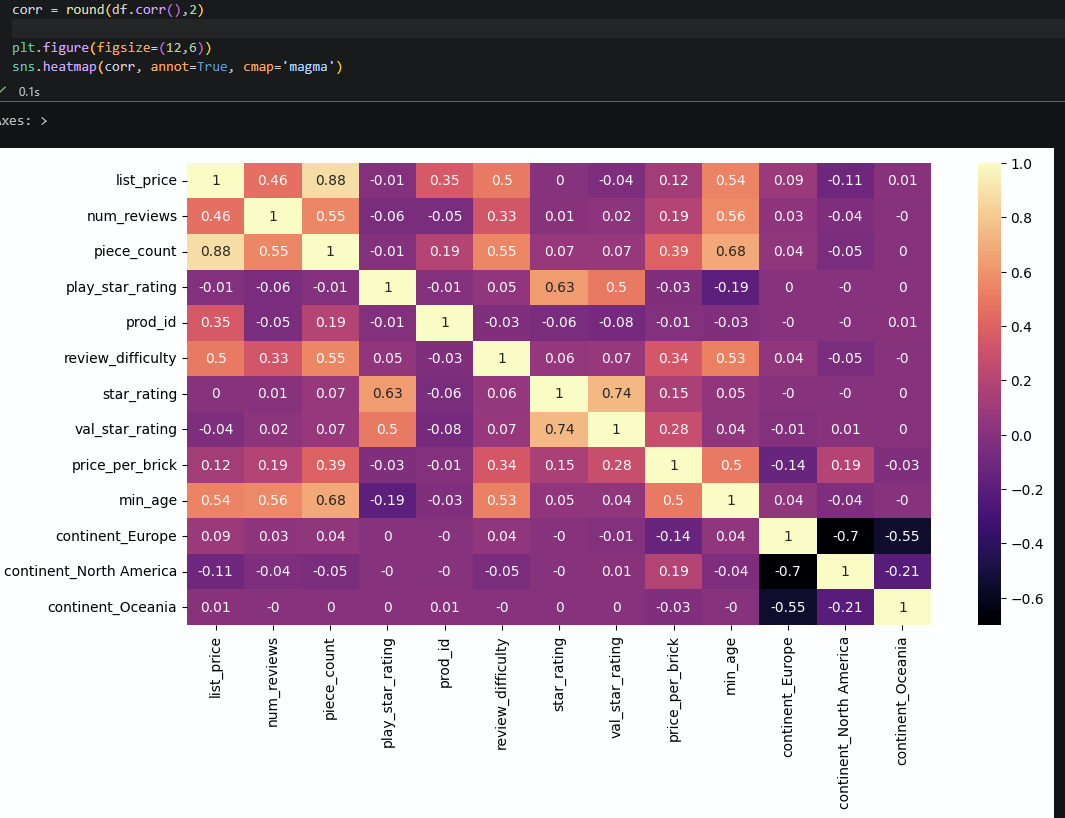

##### <b> <u>Step 2c</u>: High cardinality</b> 


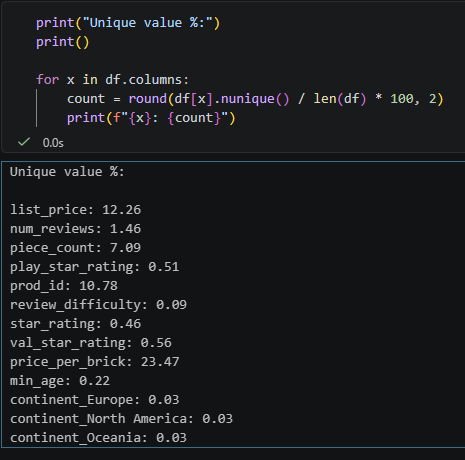 <br>

The picture above shows the low cardinality of the dataset. Only price_per_brick has many unique values, but this is expected. This column will also be dropped for ML-purposes anyway.
<i>


---

## Overlapping, noise, and correlation/associations

<br>
<br>

##### <b> <u>Step 3a</u>: Major trends</b> 

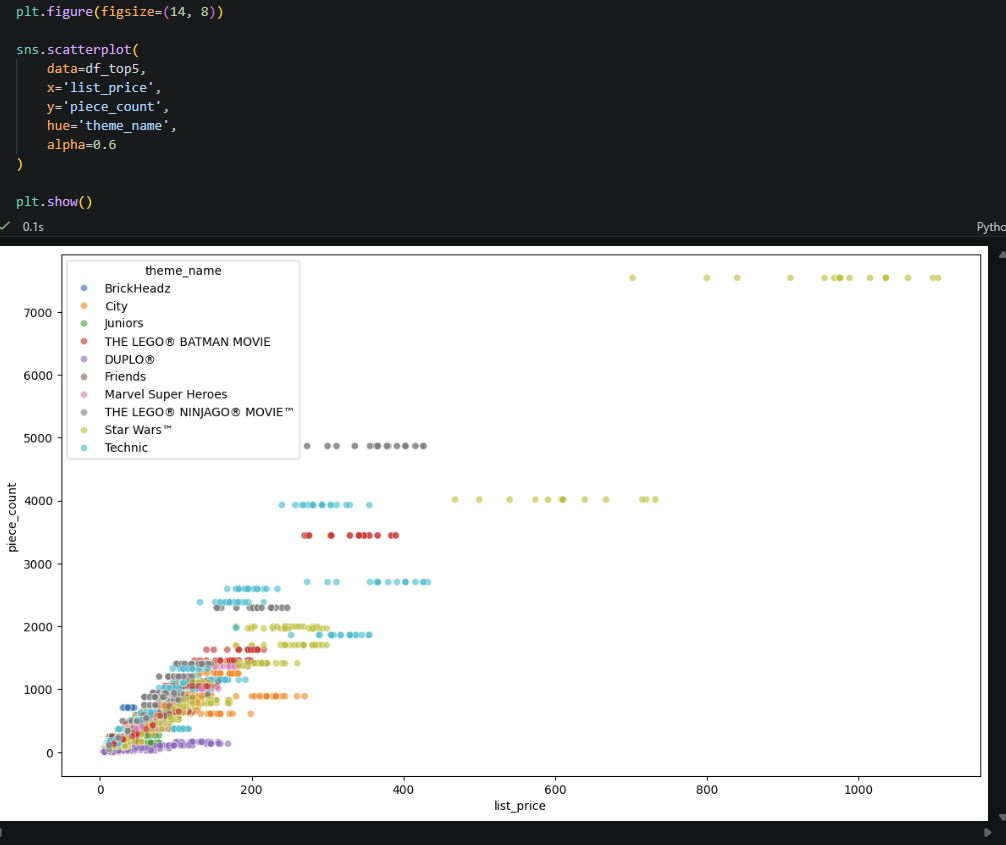

This explains the correlation between the list price and piece count. It is possible to see a slight regression in the graph.
It's also possible to see how the data is located in the dataset. Not many expensive lego, when most of the legos are in the cheaper side.


<br>

##### <b> <u>Step 3b</u>: Overlapping Data</b> 

Looking at the graph in 3a, we can see quite a lot of overlapping in down left. There are also horizontally repeated sets, which could be the same set, but in a different continent and with different currency. It is possible to see some clusters of data with the theme, but barely. I believe if my hypothesis on the repeating sets by continent is correct, it could possibly be bad for ML-training.
<i>
<br>

##### <b> <u>Step 3c</u>: Outliers & noise</b> 

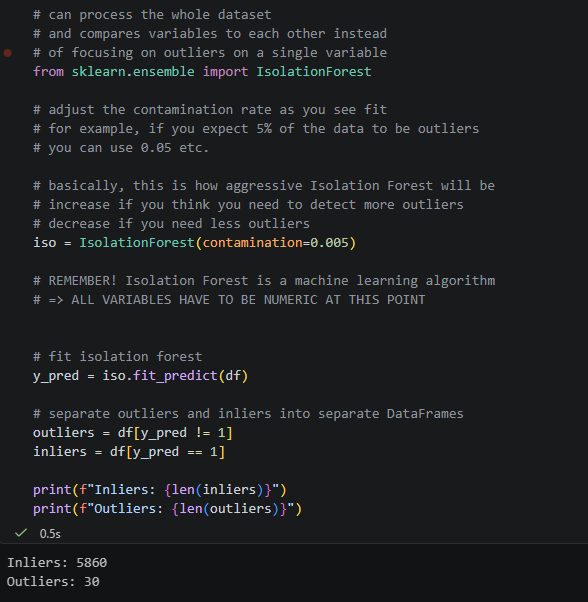

According to IsolationForest, there are not many outliers in the data. 


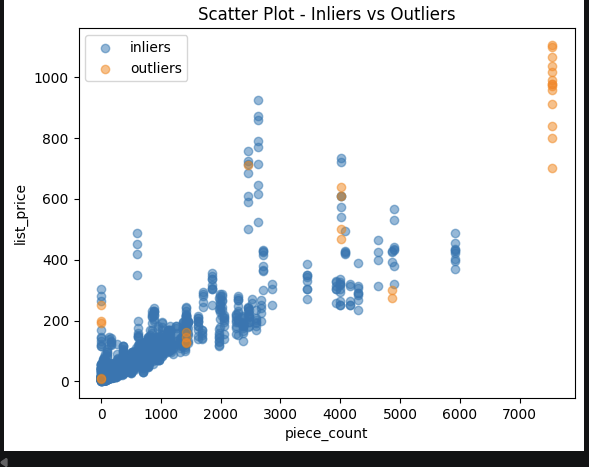

Many of the outliers are these very big and expensive Star Wars sets.

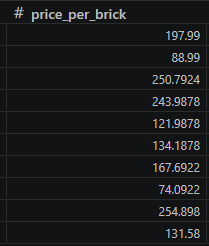

I also did the elliptic envelope, and it showed even more outliers. We can see these many 1-brick sets that cost a lot of money. They also have a very high price_per_brick ratio. These could be good to remove.


<br><br>

##### <b> <u>Step 3d</u>: Correlations & associations</b> 

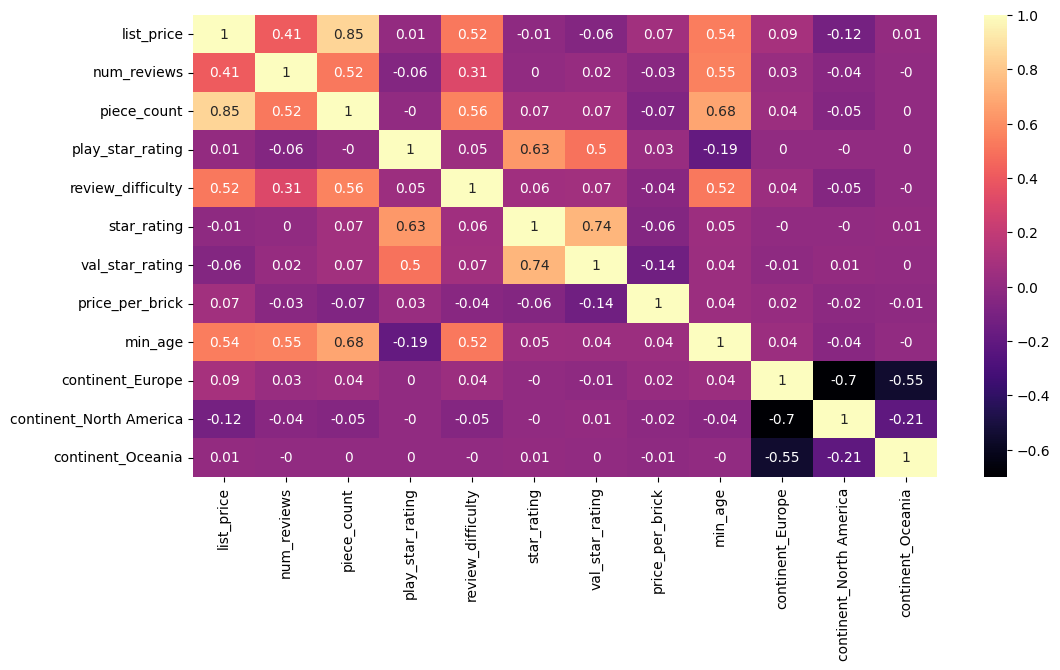

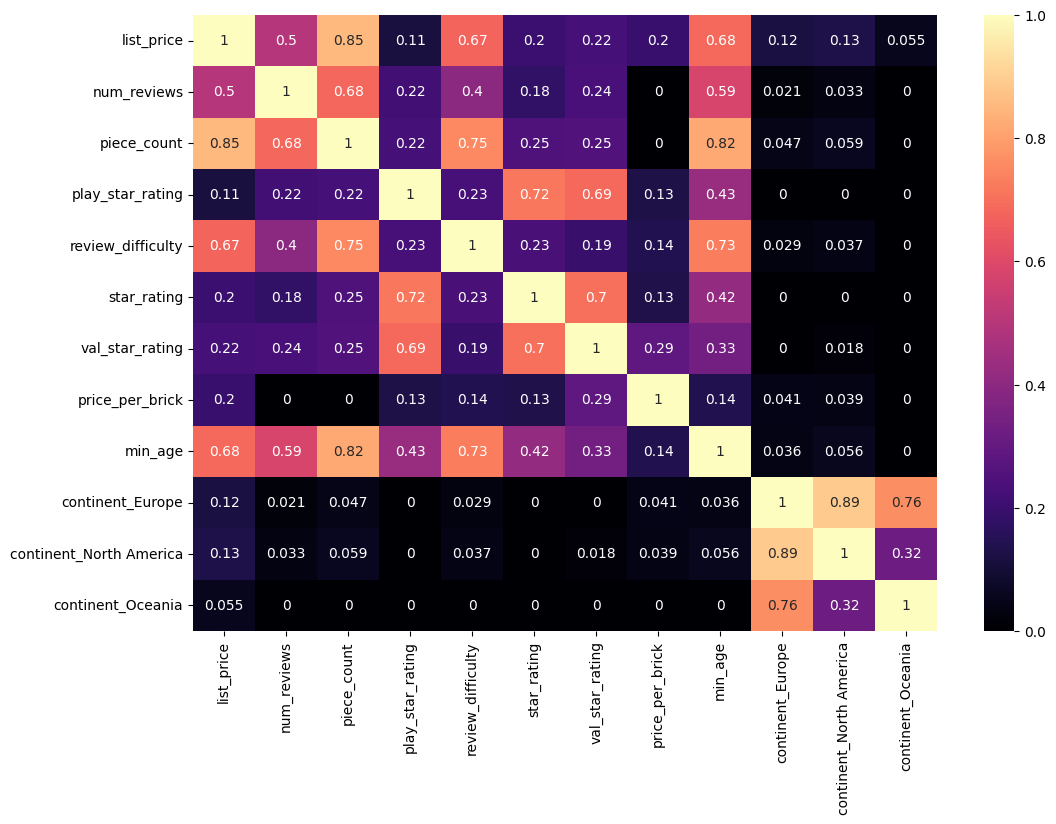

The strongest connections regarding the target variable are piece_count, review_difficulty and min_age. Also num_reviews to some extent. 

Phik matrix also shows that min_age actually seems to correlate with most of the features in the data.

What I can learn from these heatmaps though are that piece_count will be an important piece while building a neural network. The performance will likely be high with this feature. 


<br>

##### <b> <u>Step 3e</u>: Feature importances</b> 

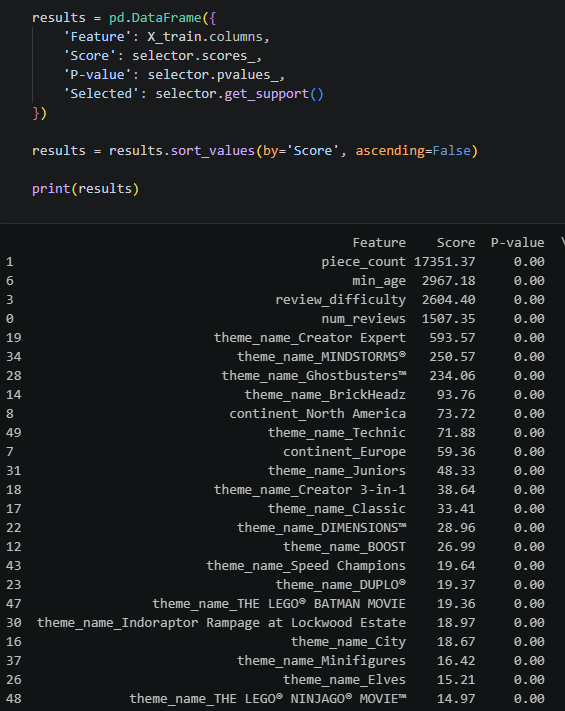

According to SelectKBest, piece_count seems easily to be the most important feature for the target variable. Min_age, review_difficulty and num_reviews come next with a nunch of themes after. Many columns, such as star_rating and val_star_rating and a bunch of theme features barely have any importance to the list_price. This can be seen in the correlations and selectkbest. Some of these can definitely be dropped. 

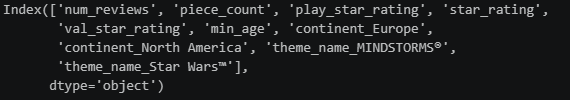

In the other hand, RFE show us completely different results. These are surprising and quite hard to explain, when the correlations do not support these findings. For more findings, I would probably have to train a neural network with these different features provided by both of these models and check the differences.

</i>


<br>
<br><br>

##### <b> <u>Step 3f</u>: Other potential problems or issues in the dataset? </b>

I am very surprised that the price_per_brick doesn't correlate to anything, but it does destroy the NN-model when training it. It only has a slight correlation to val_star_rating which makes sense, a lower price per brick would bring more value to your lego set.


---

### Summary of findings

In the end, the dataset was actually quite fun to work with. I realized midway that just dropping all the themes is probably not the best idea, but making each of them a column instead brings more insight for EDA purposes. Piece_count is easily the most important feature in the whole dataset, with min_age, review_difficulty and num_reviews being quite far behind, but still in their own small cluster. 